In [1]:
!pip install roboflow
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 104.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
from roboflow import Roboflow
rf = Roboflow(api_key="CFPqVUZkUzpq8L3aQPhe")
project = rf.workspace("noora-alkhalaqi").project("bahraini-currency-1ka60")
version = project.version(1)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bahraini-currency-1 in yolo26:: 100%|██████████| 789/789 [00:03<00:00, 231.15it/s]


In [3]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model = YOLO("yolo26s.pt")

In [5]:
from pathlib import Path

train_image = next((Path(dataset.location) / "train" / "images").glob("*"))
results = model(str(train_image))


image 1/1 /content/bahraini-currency-1/train/images/20_0019_jpg.rf.a913303d965b726fe49a6111e266c1a8.jpg: 480x640 (no detections), 18.5ms
Speed: 137.3ms preprocess, 18.5ms inference, 7.6ms postprocess per image at shape (1, 3, 480, 640)


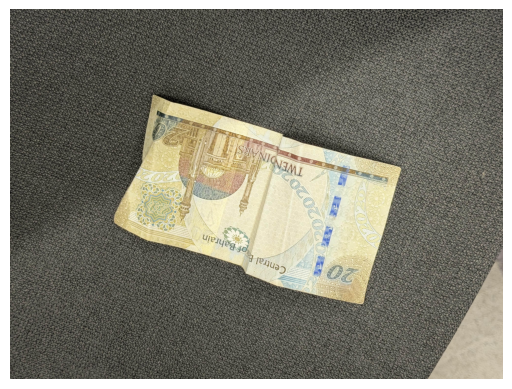

In [6]:
import matplotlib.pyplot as plt

plt.imshow(results[0].plot()[..., ::-1])
plt.axis('off')
plt.show()

In [7]:
import yaml

with open(f'{dataset.location}/data.yaml', 'r') as file:
    data = yaml.safe_load(file)

print(data['names'])

['0.5 BD', '1 BD', '10 BD', '10 fils', '100 fils', '20 BD', '25 fils', '5 BD', '5 fils', '50 fils']


In [8]:
results = model.train(
    data=f'{dataset.location}/data.yaml',
    epochs=5
)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bahraini-currency-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False,

In [9]:
finetuned_model = YOLO(model.trainer.best)

In [10]:
model = YOLO('/content/runs/detect/train/weights/best.pt')

In [11]:
results = model.predict(
    source='/content/bahraini-currency-1/valid/images',
    conf=0.25,
    save=True
)


image 1/11 /content/bahraini-currency-1/valid/images/0_5_0004_jpg.rf.5d83876075bad2716bbdc00995dd2705.jpg: 640x320 1 0.5 BD, 18.7ms
image 2/11 /content/bahraini-currency-1/valid/images/0_5_0012_jpg.rf.d2e808d12311f734e887f55abaa296fd.jpg: 480x640 1 0.5 BD, 14.9ms
image 3/11 /content/bahraini-currency-1/valid/images/0_5_0021_png.rf.f60b7e12d3002ba328b34ce88d7d54e5.jpg: 320x640 1 0.5 BD, 51.7ms
image 4/11 /content/bahraini-currency-1/valid/images/10_0014_png.rf.606e2b46af99fe21a160a5a5eba455eb.jpg: 320x640 1 10 BD, 14.1ms
image 5/11 /content/bahraini-currency-1/valid/images/1_0014_jpg.rf.e8604765f746919ff25c8202a3f2c57c.jpg: 640x384 1 1 BD, 51.2ms
image 6/11 /content/bahraini-currency-1/valid/images/1_0023_png.rf.c01fe32dcee5b9b14ca303924516d768.jpg: 320x640 1 1 BD, 16.3ms
image 7/11 /content/bahraini-currency-1/valid/images/20_0009_jpg.rf.f709214bfd4822281631d6b16eb54e1e.jpg: 640x320 1 20 BD, 14.7ms
image 8/11 /content/bahraini-currency-1/valid/images/20_0011_jpg.rf.039a921d6cda7ec21b4

In [13]:
from google.colab import files

files.download('/content/runs/detect/train/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>